
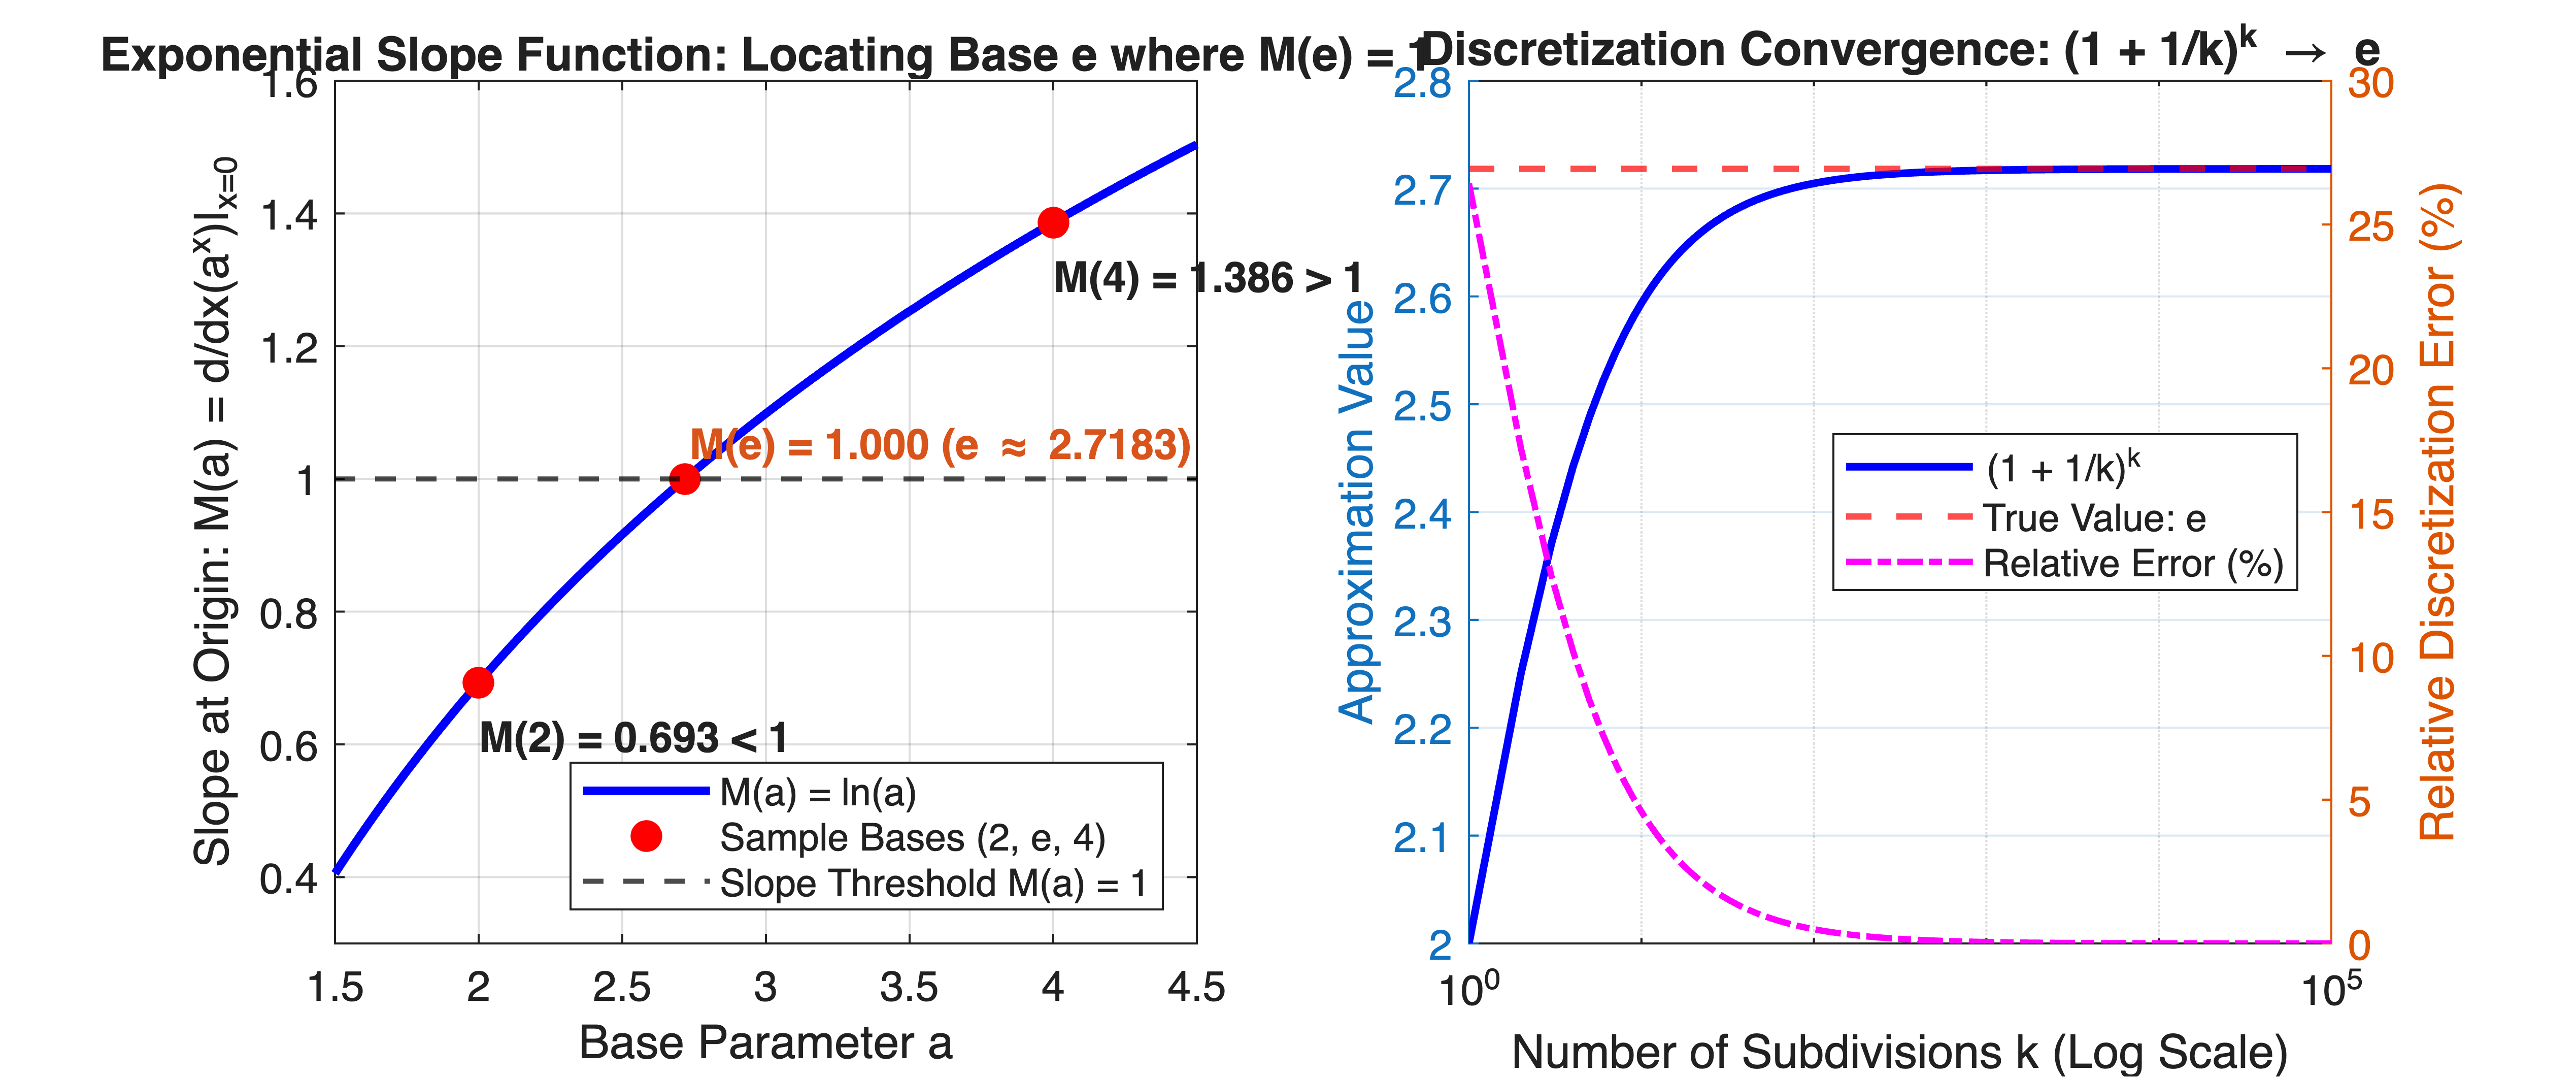

In [1]:
%% MIT 18.01 Lecture 6: Exponential Base Derivative & Euler Limit Simulation
% Mathematical Tool Application: Solves exponential growth derivatives,
% analyzes base slope factor M(a) = ln(a), and evaluates continuous-to-discrete
% discretization convergence via Euler limit formulations.


clear; clc; close all;


%% Part 1: Base Growth Rate M(a) and the Definition of Euler's Number e
% Evaluate M(a) = lim_{dx -> 0} (a^dx - 1)/dx = ln(a)
a_sweep = linspace(1.5, 4.5, 300);
M_analytic = log(a_sweep);


% Specific bases evaluated in lecture: a = 2, a = 4, and a = exp(1)
a_samples = [2.0, exp(1), 4.0];
M_samples = log(a_samples);


figure('Color', 'w', 'Position', [100, 100, 1150, 480]);


subplot(1, 2, 1);
plot(a_sweep, M_analytic, 'b-', 'LineWidth', 2, 'DisplayName', 'M(a) = ln(a)'); hold on;
plot(a_samples, M_samples, 'ro', 'MarkerSize', 7, 'MarkerFaceColor', 'r', 'DisplayName', 'Sample Bases (2, e, 4)');
yline(1.0, 'k--', 'LineWidth', 1.2, 'DisplayName', 'Slope Threshold M(a) = 1');


% Annotate specific slope points
text(2.0, log(2.0) - 0.08, sprintf('M(2) = %.3f < 1', log(2.0)), 'FontWeight', 'bold');
text(exp(1), 1.05, sprintf('M(e) = 1.000 (e \\approx %.4f)', exp(1)), 'FontWeight', 'bold', 'Color', [0.85, 0.33, 0.1]);
text(4.0, log(4.0) - 0.08, sprintf('M(4) = %.3f > 1', log(4.0)), 'FontWeight', 'bold');


grid on;
xlabel('Base Parameter a');
ylabel('Slope at Origin: M(a) = d/dx(a^x)|_{x=0}');
title('Exponential Slope Function: Locating Base e where M(e) = 1');
legend('Location', 'southeast');
xlim([1.5, 4.5]); ylim([0.3, 1.6]);
%% Part 2: Discretization Limit Convergence: (1 + 1/k)^k -> e
k_steps = round(logspace(0, 5, 200));
e_approx = (1 + 1 ./ k_steps) .^ k_steps;
e_exact = exp(1);
rel_error = abs(e_approx - e_exact) ./ e_exact;


subplot(1, 2, 2);
yyaxis left;
semilogx(k_steps, e_approx, 'b-', 'LineWidth', 1.8, 'DisplayName', '(1 + 1/k)^k'); hold on;
yline(e_exact, 'r--', 'LineWidth', 1.5, 'DisplayName', 'True Value: e');
ylabel('Approximation Value');
xlabel('Number of Subdivisions k (Log Scale)');


yyaxis right;
loglog(k_steps, rel_error * 100, 'm-.', 'LineWidth', 1.5, 'DisplayName', 'Relative Error (%)');
ylabel('Relative Discretization Error (%)');
title('Discretization Convergence: (1 + 1/k)^k \rightarrow e');
grid on;
legend('Location', 'east');